# Data format vs. token usage: exploratory analysis

**Question:** when a prompt contains a dataset, does the **format of that data** (CSV, XML, or prose) change how many tokens an LLM uses to write Python code for it? And does the **wording of the instructions** (structured vs informal) matter?

| | |
|---|---|
| **Tasks** | 6 tasks over real League of Legends esports data (`t11`–`t16`), each with its own 20-row sample |
| **The model must** | write Python that **contains the data** and defines `q1()`–`q3()`, each answering a question about it |
| **Varied** | `data_format`: `csv` vs `xml` vs `prose`, **crossed with** instruction `format`: `structured` vs `informal` |
| **Measured** | `input_tokens`, `output_tokens`, plus a validity check (answers are not graded) |
| **Calls** | 6 tasks × 3 data formats × 2 instruction formats × 5 runs = 180 |

- **Controls:** same model, temperature, max output tokens, and system prompt on every call; no extended thinking.
- **Data:** 20-row samples from the [Oracle's Elixir](https://oracleselixir.com) 2025 LoL esports match data.
- **Validity:** each response is checked for two things: `q1`–`q3` run without crashing, and every row of the data appears in the code. That way a "cheap" response that skipped the work isn't mistaken for an efficient one.

**Unit of analysis.** Each prompt is run 5 times, but those runs are repeated measurements of the *same* prompt, not independent samples. Statistical comparisons therefore use **per-task means**. Treating every row as independent would overstate certainty (pseudo-replication).

> The "How to read it" notes below explain each plot. Lines marked **Result:** describe the runs in `data/results.csv` (`qwen2.5-coder:7b` via Ollama, collected 2026-10-14). If you re-run the experiment, re-check them against the new numbers.

In [1]:
import html
import json
import re
import sys
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import HTML, Markdown

sys.path.insert(0, "../src")
from evaluate import extract_code   # pulls the code out of a saved model response

SEED = 42
RESULTS_CSV = "../data/results.csv"
MODEL = "qwen2.5-coder:7b"   # analyze one model at a time (must match config.py)

FORMATS = ["structured", "informal"]
COLORS = {"structured": "#2a78d6", "informal": "#eb6834"}  # blue / orange (colorblind-safe pair)

DATA_FORMATS = ["csv", "xml", "prose"]
# green / violet / magenta: colorblind-safe as a set; markers and labels give a second cue
DATA_COLORS = {"csv": "#008300", "xml": "#4a3aa7", "prose": "#e87ba4"}
DATA_MARKERS = {"csv": "o", "xml": "s", "prose": "D"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})

responses = pd.read_csv(RESULTS_CSV)
responses = responses[responses["model"] == MODEL].copy()
print(f"{len(responses)} rows for {MODEL}")
responses.head()

180 rows for qwen2.5-coder:7b


,task_id,format,data_format,run,model,input_tokens,output_tokens,tests_passed,tests_total,passed_all,stop_reason,timestamp
0,t12_gold_lead,informal,xml,1,qwen2.5-coder:7b,1158,1010,2,2,True,stop,2026-10-14T17:20:11+00:00
1,t11_side_winrate,informal,csv,1,qwen2.5-coder:7b,517,714,2,2,True,stop,2026-10-14T17:20:23+00:00
2,t16_support_vision,structured,csv,1,qwen2.5-coder:7b,584,1178,2,2,True,stop,2026-10-14T17:20:42+00:00
3,t11_side_winrate,structured,csv,1,qwen2.5-coder:7b,532,1016,2,2,True,stop,2026-10-14T17:20:58+00:00
4,t16_support_vision,structured,xml,1,qwen2.5-coder:7b,1366,1140,2,2,True,stop,2026-10-14T17:21:17+00:00


## 0. The tasks

Everything below is read straight from the `tasks/` folder, so it always matches the prompts the model actually received.

In [2]:
TASKS_DIR = Path("../tasks")
TASK_IDS = sorted(p.name for p in TASKS_DIR.glob("t*") if p.is_dir())

def read_task_file(task_id, name):
    return (TASKS_DIR / task_id / name).read_text(encoding="utf-8")

def wrapped(text, width=76):
    """Wrap long lines so the prompts fit side by side (keeps the original line breaks)."""
    return "\n".join(textwrap.fill(line, width) if line else "" for line in text.splitlines())

print("Tasks:", ", ".join(TASK_IDS))

Tasks: t11_side_winrate, t12_gold_lead, t13_objectives, t14_mid_kda, t15_jungle_picks, t16_support_vision


### The same data written three ways

Each prompt is an instruction template (structured or informal) with a `{DATA}` slot. The slot is filled with the same 20 rows as CSV, XML, or prose, all generated from one `sample.json` by `scripts/make_data_tasks.py`. Below are the first few rows of one task in each format. Change `EXAMPLE_DATA_TASK` to view another.

In [3]:
EXAMPLE_DATA_TASK = "t11_side_winrate"

def preview(text, data_format, n=4):
    """The first n rows of a data block (prose rows are sentences, so cut by characters instead)."""
    if data_format == "prose":
        return textwrap.fill(text[:420], 60) + " ..."
    lines = text.splitlines()
    return "\n".join(lines[:n + 1]) + "\n..."   # +1 for the CSV header / opening <rows> tag

columns = "".join(
    f'<td style="vertical-align:top; padding:0 12px"><b>data_{d}.txt</b>'
    f'<pre style="white-space:pre-wrap">{html.escape(preview(read_task_file(EXAMPLE_DATA_TASK, f"data_{d}.txt"), d))}</pre></td>'
    for d in DATA_FORMATS
)
display(Markdown(f"#### `{EXAMPLE_DATA_TASK}`: first rows in each data format"))
display(HTML(f"<table><tr>{columns}</tr></table>"))
display(Markdown("#### Its two instruction templates (the data goes where `{DATA}` is)"))
columns = "".join(
    f'<td style="vertical-align:top; padding:0 12px"><b>{fmt}.txt</b>'
    f'<pre style="white-space:pre-wrap">{html.escape(wrapped(read_task_file(EXAMPLE_DATA_TASK, fmt + ".txt"), 60))}</pre></td>'
    for fmt in FORMATS
)
display(HTML(f"<table><tr>{columns}</tr></table>"))

#### `t11_side_winrate`: first rows in each data format

"data_csv.txtgame,team,side,result,game_minutes G01,DN Freecs,blue,loss,34.1 G01,Dplus KIA,red,win,34.1 G02,BNK FEARX,blue,loss,40.1 G02,Gen.G,red,win,40.1 ...",data_xml.txt<rows> <row><game>G01</game><team>DN Freecs</team><side>blue</side><result>loss</result><game_minutes>34.1</game_minutes></row> <row><game>G01</game><team>Dplus KIA</team><side>red</side><result>win</result><game_minutes>34.1</game_minutes></row> <row><game>G02</game><team>BNK FEARX</team><side>blue</side><result>loss</result><game_minutes>40.1</game_minutes></row> <row><game>G02</game><team>Gen.G</team><side>red</side><result>win</result><game_minutes>40.1</game_minutes></row> ...,"data_prose.txtIn game G01, DN Freecs played on the blue side and lost; the game lasted 34.1 minutes. In game G01, Dplus KIA played on the red side and won; the game lasted 34.1 minutes. In game G02, BNK FEARX played on the blue side and lost; the game lasted 40.1 minutes. In game G02, Gen.G played on the red side and won; the game lasted 40.1 minutes. In game G03, Dplus KIA played on the blue side and won; the game lasted 27.5 min ..."


#### Its two instruction templates (the data goes where `{DATA}` is)

"structured.txt## Goal Write Python code that answers three questions about the data below. ## Data Here is some League of Legends esports match data, one row per team per game: {DATA} ## Requirements 1. Put the data directly in the code as Python data structures. Do not read it from a file. 2. Define a function `q1()` that returns the win rate of blue-side teams, as a number between 0 and 1. 3. Define a function `q2()` that returns the average length in minutes of the games won by the red-side team. 4. Define a function `q3()` that returns the name of the team with the most wins. ## Output Respond with only Python code.","informal.txthey, I've got some League of Legends esports match data here, one row per team per game: {DATA} can you write me some Python that answers a few things about it? I'd like a function q2() that gives the average length in minutes of the games the red-side team won, and q1() should return the win rate of blue-side teams as a number between 0 and 1. Oh, and q3() should return the name of the team with the most wins. Please put the data right in the code as Python data structures instead of reading it from a file. Just send back the Python code, nothing else."


### All 6 tasks

In [4]:
data_rows = []
for task_id in TASK_IDS:
    row = {"task_id": task_id, "rows": len(json.loads(read_task_file(task_id, "sample.json")))}
    for d in DATA_FORMATS:
        row[f"{d} chars"] = len(read_task_file(task_id, f"data_{d}.txt"))
    data_rows.append(row)
data_table = pd.DataFrame(data_rows).set_index("task_id")

# Input tokens per data format (averaged over both instruction formats), as the model counted them.
input_by_format = responses.groupby(["task_id", "data_format"])["input_tokens"].mean().unstack()
for d in DATA_FORMATS:
    if d in input_by_format:
        data_table[f"{d} input tokens"] = input_by_format[d].round(0)
data_table

,rows,csv chars,xml chars,prose chars,csv input tokens,xml input tokens,prose input tokens
task_id,,,,,,,
t11_side_winrate,20,627,2487,1752,524.0,1062.0,722.0
t12_gold_lead,20,617,2477,2062,515.0,1168.0,825.0
t13_objectives,20,794,3397,2412,558.0,1417.0,855.0
t14_mid_kda,20,801,3287,1812,574.0,1356.0,716.0
t15_jungle_picks,20,459,2084,1209,380.0,894.0,498.0
t16_support_vision,20,803,3639,2064,572.0,1354.0,787.0


**How to read it:** the `chars` columns measure the data block alone. The `input tokens` columns are the whole prompt (instructions + data + system prompt) as the model counted it, averaged over the structured and informal versions.

**Result:** the XML data block is about 4× as many characters as the CSV one (2,084–3,639 vs 459–803), because every value is wrapped in an opening and closing tag. As whole prompts, XML costs 2.0–2.5× the CSV prompt in tokens, and prose 1.25–1.6×.

## 1. Sanity checks and validity

In [5]:
print("Runs per task x instruction format x data format (every cell should equal N_RUNS):")
display(responses.pivot_table(index="task_id", columns=["format", "data_format"], values="run", aggfunc="count"))
print("stop_reason counts:")
display(responses["stop_reason"].value_counts())

# Validity = both checks passed: q1-q3 run, and every row of the data appears in the code.
responses["valid"] = responses["passed_all"]
print("Share of valid responses (data format x instruction format):")
display(responses.pivot_table(index="data_format", columns="format", values="valid", aggfunc="mean").loc[DATA_FORMATS, FORMATS].round(2))
print("Checks passed per response (2 = valid; 1 = usually 'contains all the data but crashed'):")
display(responses.groupby("data_format")["tests_passed"].value_counts().unstack(fill_value=0).loc[DATA_FORMATS])
invalid = responses[~responses["valid"]]
print(f"Invalid responses: {len(invalid)} of {len(responses)}")
display(invalid[["task_id", "format", "data_format", "run", "tests_passed", "output_tokens"]])

valid = responses[responses["valid"]].copy()
valid["total_tokens"] = valid["input_tokens"] + valid["output_tokens"]

Runs per task x instruction format x data format (every cell should equal N_RUNS):


format             informal           structured          
data_format             csv prose xml        csv prose xml
task_id                                                   
t11_side_winrate          5     5   5          5     5   5
t12_gold_lead             5     5   5          5     5   5
t13_objectives            5     5   5          5     5   5
t14_mid_kda               5     5   5          5     5   5
t15_jungle_picks          5     5   5          5     5   5
t16_support_vision        5     5   5          5     5   5

stop_reason counts:


stop_reason
stop    180
Name: count, dtype: int64

Share of valid responses (data format x instruction format):


format,structured,informal
data_format,,
csv,0.97,0.90
xml,1.00,0.80
prose,0.87,0.73


Checks passed per response (2 = valid; 1 = usually 'contains all the data but crashed'):


tests_passed,1,2
data_format,,
csv,4,56
xml,6,54
prose,12,48


Invalid responses: 22 of 180


,task_id,format,data_format,run,tests_passed,output_tokens
11,t16_support_vision,informal,prose,1,1,668
20,t15_jungle_picks,informal,xml,1,1,956
31,t13_objectives,structured,prose,1,1,811
40,t15_jungle_picks,informal,xml,5,1,828
49,t11_side_winrate,structured,csv,5,1,706
63,t15_jungle_picks,informal,prose,5,1,828
66,t11_side_winrate,informal,prose,5,1,653
83,t15_jungle_picks,informal,xml,3,1,889
84,t11_side_winrate,informal,xml,4,1,1059
85,t13_objectives,structured,prose,3,1,925


**How to read it:** every cell of the first table should equal N_RUNS, and every stop reason should be `stop`. A response is **invalid** if its code crashed or if some rows of the data are missing from it. The two checks are independent, so a response scoring 1 of 2 either contains all the data but crashed, or runs but left rows out. The raw response in `data/raw/` tells which. Every chart below uses **valid responses only**, so the token numbers describe complete work.

**Result:** all 180 rows are present (5 per cell), and every response ended normally. **158 of 180 (88%) are valid**: CSV 56/60, XML 54/60, prose 48/60. Informal instructions were less often valid in every data format (0.90 / 0.80 / 0.73, against 0.97 / 1.00 / 0.87 for structured). Reading the 22 invalid answers: **20 contain all the data but crash** with ordinary bugs (`NameError`, `KeyError`, `ZeroDivisionError`, a syntax error). Only **2 skipped the data**: `t13` informal XML run 4 copied 2 rows and then wrote `# ... (rest of the data)`, and `t11` informal prose run 3 replaced the rows with an invented per-team summary. Shortcutting was rare (2 of 180).

## 2. Summary table: tokens by data format and instruction format

In [6]:
summary2 = valid.groupby(["data_format", "format"])[["input_tokens", "output_tokens", "total_tokens"]].agg(["mean", "median"]).round(0)
summary2.loc[DATA_FORMATS]

input_tokens         output_tokens          \
                               mean  median          mean  median   
data_format format                                                  
csv         informal          525.0   546.0        1050.0  1139.0   
            structured        531.0   570.0        1037.0  1042.0   
xml         informal         1240.0  1342.0        1141.0  1146.0   
            structured       1219.0  1272.0        1097.0  1100.0   
prose       informal          713.0   714.0         837.0   796.0   
            structured        731.0   729.0         834.0   766.0   

                       total_tokens          
                               mean  median  
data_format format                           
csv         informal         1575.0  1699.0  
            structured       1569.0  1567.0  
xml         informal         2381.0  2488.0  
            structured       2316.0  2372.0  
prose       informal         1550.0  1534.0  
            structured       1565.0  1543.0

**How to read it:** input tokens show what each data format costs to *send*. Output tokens show what it costs the model to *write the data back out* as Python. Total is the sum, i.e. the cost of one complete request.

**Result:** per request, CSV prompts average about 528 input tokens, prose about 722, and XML about 1,230. Output runs the other way for prose: CSV about 1,044, XML about 1,119, **prose about 836**. In **total**, prose (~1,558) and CSV (~1,572) cost about the same, while XML (~2,349) costs about 50% more. Within a data format, structured vs informal instructions change output by at most ~45 tokens.

## 3. Output tokens across data formats (interaction plot)

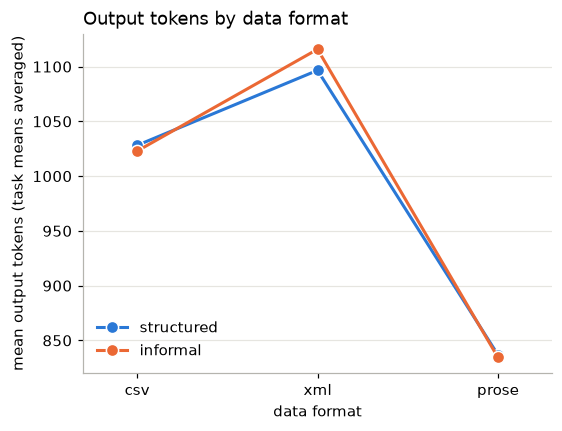

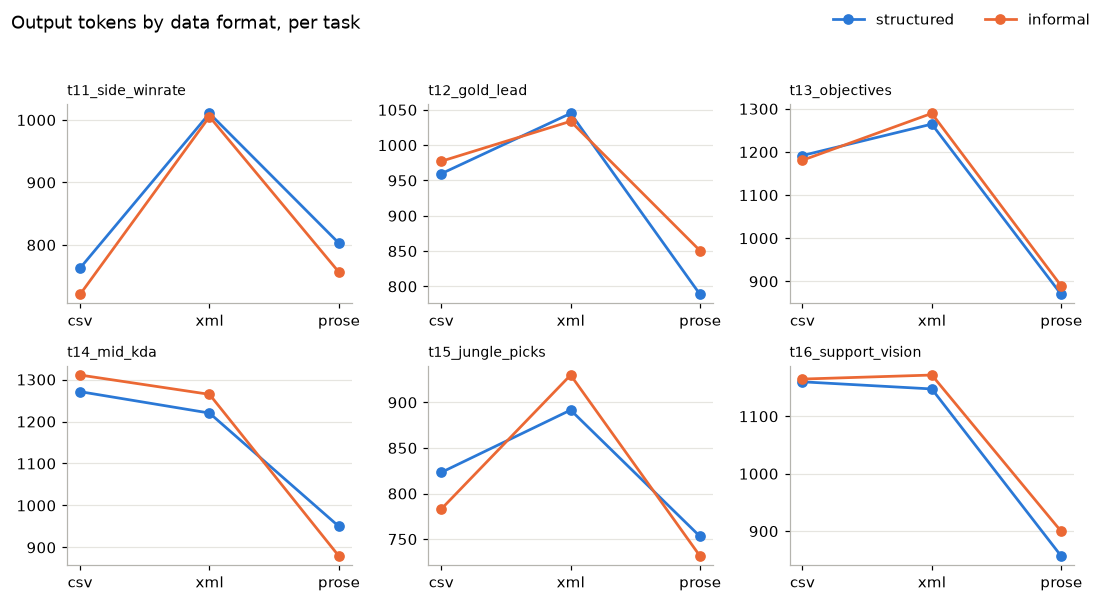

In [7]:
cell = valid.groupby(["task_id", "data_format", "format"])["output_tokens"].mean().reset_index()
means = cell.groupby(["data_format", "format"])["output_tokens"].mean().unstack().loc[DATA_FORMATS, FORMATS]

fig, ax = plt.subplots(figsize=(5.5, 4))
x = np.arange(len(DATA_FORMATS))
for f in FORMATS:
    ax.plot(x, means[f], marker="o", markersize=8, linewidth=2, color=COLORS[f], markeredgecolor="white", label=f)
ax.legend(frameon=False, loc="lower left")
ax.set_xticks(x, DATA_FORMATS)
ax.set_xlim(-0.3, len(DATA_FORMATS) - 0.7)
ax.set_xlabel("data format")
ax.set_ylabel("mean output tokens (task means averaged)")
ax.set_title("Output tokens by data format", loc="left")
ax.grid(axis="x", visible=False)
plt.show()

# The same, task by task (small multiples).
tasks2 = sorted(cell["task_id"].unique())
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), sharey=False)
for ax, task_id in zip(axes.flat, tasks2):
    sub_cell = cell[cell["task_id"] == task_id].pivot(index="data_format", columns="format", values="output_tokens").reindex(DATA_FORMATS)
    for f in FORMATS:
        ax.plot(x, sub_cell[f], marker="o", markersize=6, linewidth=1.8, color=COLORS[f], label=f)
    ax.set_xticks(x, DATA_FORMATS)
    ax.set_title(task_id, fontsize=9, loc="left")
    ax.grid(axis="x", visible=False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="upper right", ncol=2)
fig.suptitle("Output tokens by data format, per task", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**How to read it:** if the lines rise from CSV to XML or prose, the model writes more when it has to convert a wordier format into Python. If the two lines run **parallel**, instruction format and data format act independently. If they **cross or diverge**, the effect of one depends on the other (an *interaction*). The small multiples show whether every task follows the same pattern.

**Result:** the two lines nearly overlap, so there's **no interaction**: instruction format doesn't change how data format affects output. XML gave the most output and prose the least on average. Task by task, prose was lowest in 5 of 6 tasks (not `t11_side_winrate`), and XML was highest in 4 of 6. CSV was highest in `t14_mid_kda` and tied with XML in `t16_support_vision`.

## 4. Input tokens by data format (what each format costs to send)

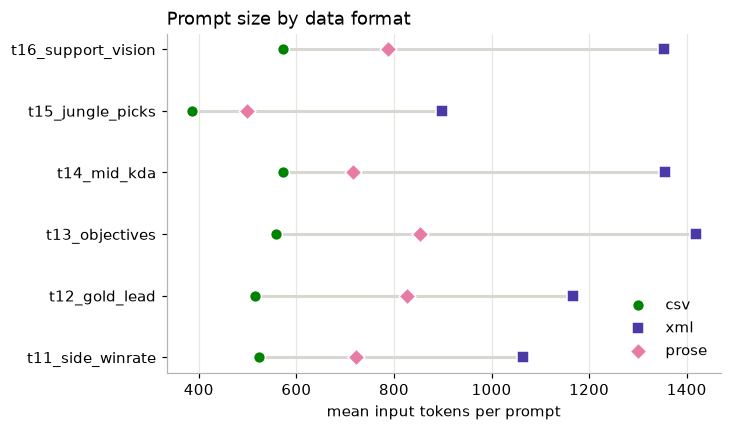

Input tokens relative to CSV, per task:


,xml / csv,prose / csv
task_id,,
t11_side_winrate,2.03,1.38
t12_gold_lead,2.27,1.61
t13_objectives,2.54,1.53
t14_mid_kda,2.36,1.25
t15_jungle_picks,2.33,1.29
t16_support_vision,2.37,1.38


In [8]:
inp = valid.groupby(["task_id", "data_format"])["input_tokens"].mean().unstack()[DATA_FORMATS]

fig, ax = plt.subplots(figsize=(6.5, 4))
y = np.arange(len(inp))
ax.hlines(y, inp.min(axis=1), inp.max(axis=1), color="#d8d7d1", linewidth=2, zorder=1)
for d in DATA_FORMATS:
    ax.scatter(inp[d], y, s=60, color=DATA_COLORS[d], marker=DATA_MARKERS[d], edgecolor="white", linewidth=1, zorder=2, label=d)
ax.set_yticks(y, inp.index)
ax.set_xlabel("mean input tokens per prompt")
ax.set_title("Prompt size by data format", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.show()

ratios = pd.DataFrame({f"{d} / csv": inp[d] / inp["csv"] for d in ["xml", "prose"]})
print("Input tokens relative to CSV, per task:")
display(ratios.round(2))

**How to read it:** each row is one task, and the three markers show its prompt size in each data format. The table shows how many times bigger the XML and prose prompts are than the CSV one.

**Result:** the order is the same in every task: CSV < prose < XML. XML prompts are 2.0–2.5× the CSV size and prose 1.25–1.6×. The extra XML cost comes from repeating each column name twice per row as tags.

## 5. How much of the input comes back as output?

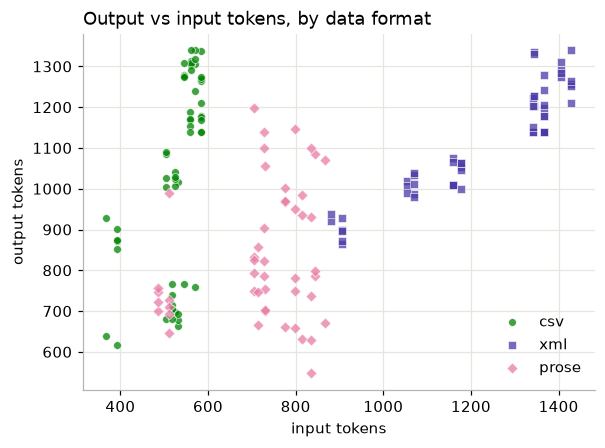

Output tokens per input token (task means averaged):


,mean output / input
data_format,
csv,1.97
xml,0.92
prose,1.16


In [9]:
valid["output_per_input"] = valid["output_tokens"] / valid["input_tokens"]

fig, ax = plt.subplots(figsize=(6, 4.2))
for d in DATA_FORMATS:
    sub_rows = valid[valid["data_format"] == d]
    ax.scatter(sub_rows["input_tokens"], sub_rows["output_tokens"], s=26, alpha=0.75, color=DATA_COLORS[d],
               marker=DATA_MARKERS[d], edgecolor="white", linewidth=0.5, label=d)
ax.set_xlabel("input tokens")
ax.set_ylabel("output tokens")
ax.set_title("Output vs input tokens, by data format", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()

print("Output tokens per input token (task means averaged):")
ratio = valid.groupby(["task_id", "data_format"])["output_per_input"].mean().unstack()[DATA_FORMATS]
display(ratio.mean().round(2).to_frame("mean output / input"))

**How to read it:** each dot is one response. Because the model rewrites the data as Python, output tends to grow with input. But Python dictionaries cost about the same tokens however the data arrived, so a verbose format (XML) may show a *lower* output-to-input ratio. Its extra tokens are paid on input, not repeated on output.

**Result:** output per input token is about **1.97 for CSV**, 1.16 for prose, and **0.92 for XML**. CSV is the cheapest to send, but the model expands it the most when it writes it back as Python dicts. XML's verbosity is paid on input and not repeated on output, since Python dicts cost about the same however the data arrived. The CSV responses form two clusters (around 700 and 1,200–1,300 output tokens). Section 7 shows those are the two storage styles.

## 6. Paired comparisons within task

In [10]:
def describe_diff(diff, label, n_boot=10_000):
    """Mean difference with a bootstrap 95% CI (resampling pairs) and a Wilcoxon signed-rank p-value."""
    rng = np.random.default_rng(SEED)
    boot = rng.choice(diff.to_numpy(), size=(n_boot, len(diff)), replace=True).mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    try:
        p = stats.wilcoxon(diff).pvalue
    except ValueError:
        p = np.nan
    return {"comparison": label, "n pairs": len(diff), "mean diff": round(diff.mean(), 1),
            "bootstrap 95% CI": f"[{lo:.1f}, {hi:.1f}]", "wilcoxon p": round(p, 4) if not np.isnan(p) else np.nan}

# Data format: per-task means averaged over instruction formats (6 pairs per comparison).
per_task = valid.groupby(["task_id", "data_format"])[["input_tokens", "output_tokens"]].mean().unstack()
rows = []
for metric in ["output_tokens", "input_tokens"]:
    for d in ["xml", "prose"]:
        rows.append(describe_diff(per_task[metric][d] - per_task[metric]["csv"], f"{metric}: {d} - csv"))
    rows.append(describe_diff(per_task[metric]["prose"] - per_task[metric]["xml"], f"{metric}: prose - xml"))

# Instruction format: one pair per task x data format (18 pairs).
per_cell = valid.groupby(["task_id", "data_format", "format"])[["input_tokens", "output_tokens"]].mean().unstack()
for metric in ["output_tokens", "input_tokens"]:
    diff = (per_cell[(metric, "informal")] - per_cell[(metric, "structured")]).dropna()
    rows.append(describe_diff(diff, f"{metric}: informal - structured"))

pd.DataFrame(rows).set_index("comparison")

,n pairs,mean diff,bootstrap 95% CI,wilcoxon p
comparison,,,,
output_tokens: xml - csv,6,78.2,"[5.1, 163.8]",0.1562
output_tokens: prose - csv,6,-191.4,"[-302.9, -67.4]",0.0625
output_tokens: prose - xml,6,-269.5,"[-332.7, -210.0]",0.0312
input_tokens: xml - csv,6,688.5,"[585.8, 786.6]",0.0312
input_tokens: prose - csv,6,212.9,"[156.1, 271.6]",0.0312
input_tokens: prose - xml,6,-475.6,"[-565.7, -388.2]",0.0312
output_tokens: informal - structured,18,3.9,"[-13.1, 20.3]",0.6705
input_tokens: informal - structured,18,-21.8,"[-23.3, -20.1]",0.0002


**How to read it:** each row compares two conditions *within the same task*, so differences between tasks cancel out. Data-format comparisons have only 6 pairs, and with 6 pairs the smallest possible Wilcoxon p-value is 0.03, so read the CI and the direction rather than the p-value. The last two rows compare the instruction formats (one pair per task × data format, 18 pairs).

**Result:** for **input**, all six tasks agree: XML adds about 690 tokens over CSV (CI [586, 787]) and prose about 210 (CI [156, 272]). For **output**, prose used about 190 fewer tokens than CSV (CI [−303, −67]) and about 270 fewer than XML (CI [−333, −210], lower in all 6 tasks). XML vs CSV output is unclear (+78, CI [5, 164], p = 0.16). Instruction format **doesn't change output** (+4 tokens, CI [−13, 20], p = 0.67), probably because most of the output is copied data. The informal templates were still about 22 tokens shorter to send.

## 7. How did the model store the data?

In [11]:
def storage_style(code_text):
    """How the model wrote the 20 rows into its code: dicts with a key per value, or bare tuples/lists."""
    dict_rows = code_text.count('{"') + code_text.count("{'")          # {"team": ..., "side": ...}
    tuple_rows = sum(line.strip()[:2] in ('("', "('", '["', "['")      # ("DN Freecs", "blue", ...)
                     for line in code_text.splitlines())
    if dict_rows >= 15:
        return "dicts with keys"
    if tuple_rows >= 15:
        return "tuples/lists"
    return "other"

safe_model = MODEL.replace(":", "-").replace("/", "-")
style_rows = []
for path in Path("../data/raw").glob(f"*__{safe_model}.txt"):
    task_id, fmt, data_format, run, _ = path.stem.split("__")
    if data_format not in DATA_FORMATS:
        continue  # e.g. leftover files from earlier runs
    code_text = extract_code(path.read_text(encoding="utf-8"))
    style_rows.append({"task_id": task_id, "format": fmt, "data_format": data_format,
                       "run": int(run.removeprefix("run")), "style": storage_style(code_text)})
styles = pd.DataFrame(style_rows).merge(valid, on=["task_id", "format", "data_format", "run"])

print("How often each storage style was used (valid responses):")
display(pd.crosstab(styles["data_format"], styles["style"]).loc[DATA_FORMATS])
print("Mean output tokens by storage style:")
display(styles.groupby("style")["output_tokens"].agg(["count", "mean"]).round(0))
print("Mean output tokens by data format and storage style:")
display(styles.groupby(["data_format", "style"])["output_tokens"].agg(["count", "mean"]).round(0).loc[DATA_FORMATS])

How often each storage style was used (valid responses):


style,dicts with keys,other,tuples/lists
data_format,,,
csv,42,0,14
xml,54,0,0
prose,17,2,29


Mean output tokens by storage style:


,count,mean
style,,
dicts with keys,113,1118.0
other,2,606.0
tuples/lists,43,726.0


Mean output tokens by data format and storage style:


count    mean
data_format style                         
csv         dicts with keys     42  1158.0
            tuples/lists        14   700.0
xml         dicts with keys     54  1116.0
prose       dicts with keys     17  1028.0
            other                2   606.0
            tuples/lists        29   739.0

**How to read it:** this reads the saved answers in `data/raw/` (not committed to git, so it needs a local run) and classifies how the model wrote the 20 rows into Python: as **dicts with keys**, which repeat the column names on every row (`{"team": "Gen.G", "side": "red", ...}`), or as compact **tuples/lists** (`("Gen.G", "red", ...)`).

**Result:** storage style is the main driver of output tokens. Dict-with-keys answers averaged about 1,120 output tokens, while tuple/list answers averaged about 730, roughly 35% fewer for the same 20 rows. Data format strongly influences which style the model picks. From **XML**, whose tags already name every value, it used dicts in every valid response. From **CSV**, which has a header row, it mostly used dicts (42 of 56). From **prose**, which has no column names at all, it mostly used tuples (29 of 48). Within CSV alone, the dict answers averaged about 1,160 tokens against 700 for tuples. So prose's low output count in sections 2–6 mostly reflects this choice of storage style, not the prose itself.

## Summary

- **XML is the expensive format:** about 2.3× the input of CSV and about 50% more total tokens per request.
- **CSV is cheapest to send** but is rewritten most expansively on output.
- **Prose costs more to send than CSV** but led to the least output, so CSV and prose come out about even in total.
- **The output differences mostly come from how the model chose to store the data** (section 7): dicts with a column name on every value cost about 35% more output than bare tuples. Data format steers that choice.
- **Instruction format barely mattered** once the data was in the prompt, and it didn't interact with data format.
- **Validity:** 88% of responses were valid. Almost all failures were ordinary bugs, and only 2 of 180 skipped copying the data.

**Caveats:** one small local model (`qwen2.5-coder:7b`) at temperature 0.7, 6 data tasks of 20 rows each, one sentence template per row for prose, and a deliberately copy-heavy task design ("put the data in the code"). With 6 tasks, Wilcoxon p-values can't go below 0.03, so the direction-consistency counts and CIs carry more weight than the p-values. The storage-style finding is an observed pattern: the model chose the style itself.